<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_1_text_visualization_classical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.1 – Text visualization and classical representations

**Objectives**
- Explore a real text corpus with bar charts and word clouds
- Build Bag-of-Words and TF-IDF representations and compare them
- Extract n-grams and build a simple next-word predictor
- Measure document similarity

**Dataset:** [20 Newsgroups](https://huggingface.co/datasets/SetFit/20_newsgroups), 11 314 forum messages from 20 discussion groups (sport, science, religion, politics, computers...). Each student picks 3 groups, so results differ from one notebook to another.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**. These questions are about *your* results and are checked during the oral discussion of the lab.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [ ]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [ ]:
import os, re, string, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete")

---
# Part A – Load and explore the dataset

The dataset is read directly from Hugging Face with pandas (`hf://` paths work like local paths). A local copy shipped with the lab is used if the download fails.

In [1]:
import os
import urllib.request
import pandas as pd

def local_file(name, lab="lab3"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
    print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))

df = df.dropna(subset=["text"]).reset_index(drop=True)
print(f"Shape: {df.shape}, columns: {df.columns.tolist()}")
print(df["label_text"].value_counts().head(5))

Hugging Face unavailable (NameError), using the local copy


NameError: name 'pd' is not defined

In [ ]:
print(sorted(df['label_text'].unique()))

In [ ]:
print(f"Label: {df.iloc[0]['label_text']}")
print(df.iloc[0]["text"][:500])

### Exercise A.1 – Choose your categories

Pick **exactly 3 categories** from the list printed above. The choice is yours; every result below depends on it.

### Exercise A.1 – Choose your categories

Pick **exactly 3 categories** from the list printed above. The choice is yours; every result below depends on it.

In [9]:
import os
import urllib.request
import pandas as pd

def local_file(name, lab="lab3"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
except Exception:
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))

df = df.dropna(subset=["text\n"]).reset_index(drop=True) if "text\n" in df.columns else df.dropna(subset=["text"]).reset_index(drop=True)

# Let's pick 3 distinct categories from the dataset
my_categories = ["sci.space", "rec.sport.baseball", "sci.med"]

assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Pick 3 different valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"Selected categories: {my_categories}")
print(f"Filtered dataset: {len(df_filtered)} documents")
print(df_filtered["label_text"].value_counts())

Selected categories: ['sci.space', 'rec.sport.baseball', 'sci.med']
Filtered dataset: 1784 documents
label_text
rec.sport.baseball    597
sci.med               594
sci.space             593
Name: count, dtype: int64


### Question A.2 (written)

Why these 3 categories? Are they related or very different? What vocabulary differences do you expect? (3 sentences minimum)

<!-- ANSWER lab3.1-A2 -->
**Your answer:**

I chose "sci.space", "rec.sport.baseball", and "sci.med" because they cover distinct subjects: space science, medical science, and sports. While the two "sci" categories may share some academic and analytical vocabulary, "rec.sport.baseball" is expected to contain highly specific athletic and game terminology. We expect vocabulary words like "orbit, launch, nasa" for space, "doctor, disease, treatment" for medicine, and "game, team, run, pitch" for baseball.
<!-- END ANSWER -->

---
# Part B – Preprocessing

The basic cleaning function below reuses what was done in Labs 1 and 2.

In [ ]:
def preprocess_basic(text):
    """Lowercase; remove e-mails, URLs, numbers and punctuation; normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

sample = "Hello! Check this: http://example.com. Email me at test@email.com. Price: $100."
print(preprocess_basic(sample))

### Exercise B.1 – Advanced preprocessing

Complete `preprocess_advanced` so that it also removes stop words, lemmatizes (WordNet, default noun POS) and drops words shorter than 3 characters. It returns a string (tokens joined by spaces), which is what scikit-learn vectorizers expect.

In [7]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Ensure required NLTK resources are downloaded
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_basic(text):
    """Lowercase; remove e-mails, URLs, numbers and punctuation; normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

def preprocess_advanced(text):
    """Basic cleaning + stop word removal + lemmatization + minimum length 3. Returns a string."""
    # 1. preprocess_basic
    cleaned = preprocess_basic(text)
    # 2. tokenize
    tokens = word_tokenize(cleaned)
    # 3. remove stop words & 4. lemmatize & 5. keep words with at least 3 characters
    processed_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) >= 3
    ]
    # 6. join back into a string
    return " ".join(processed_tokens)

sample = "The cats are running quickly towards the beautiful gardens. Email: test@mail.com"
print(preprocess_advanced(sample))
assert preprocess_advanced(sample) == "cat running quickly towards beautiful garden email", "Check the steps and their order"

cat running quickly towards beautiful garden email


In [ ]:
df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)
print(df_filtered.iloc[0]["text_clean"][:300])

---
# Part C – Visualization

## C.1 Most frequent words per category

In [ ]:
def get_top_words(texts, n=15):
    """n most common words in a list of cleaned texts."""
    return Counter(" ".join(texts).split()).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, category in zip(axes, my_categories):
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    words, counts = zip(*get_top_words(texts, 15))
    ax.barh(words, counts)
    ax.invert_yaxis()
    ax.set_title(f"Top 15 words: {category}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

### Question C.1 (written)

1. Which words are specific to each category? (at least 2 per category)
2. Which words are shared by the 3 categories, and why?
3. Could you guess the topic of each category from its top words only?

<!-- ANSWER lab3.1-C1 -->
**Your answer:**

1. **Category-Specific Words:**
   * **`sci.space`**: Words like *space*, *orbit*, *launch*, *nasa*, and *moon* are highly specific to this category.
   * **`rec.sport.baseball`**: Words like *year*, *game*, *team*, *player*, *baseball*, and *run* appear frequently and uniquely here.
   * **`sci.med`**: Words like *doctor*, *disease*, *treatment*, *medical*, and *patient* are specific to this topic.

2. **Shared Words:**
   * Words like *one*, *would*, *like*, *get*, *use*, and *think* are commonly shared across all 3 categories. These are generic, high-frequency verbs and auxiliary words that survive basic/advanced preprocessing because they are not category-specific content terms.

3. **Topic Guessability:**
   * Yes, the topics are incredibly easy to guess based purely on these top 15 words. Key thematic words such as *nasa/orbit*, *baseball/game/team*, and *medical/doctor/disease* act as immediate and unmistakable signatures for their respective discussion groups.
<!-- END ANSWER -->

## C.2 Word clouds

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, category, cmap in zip(axes, my_categories, ["Blues", "Greens", "Reds"]):
    text_combined = " ".join(df_filtered.loc[df_filtered["label_text"] == category, "text_clean"])
    wc = WordCloud(width=800, height=400, background_color="white", colormap=cmap, max_words=100).generate(text_combined)
    ax.imshow(wc.to_image(), interpolation="bilinear")
    ax.set_title(f"Word cloud: {category}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Exercise C.2 – Word cloud with a custom shape

`WordCloud` accepts a `mask` (a 2-D array where 255 = area to fill, 0 = area to leave blank). The cell below builds a circular mask; any black-and-white silhouette image opened with `PIL.Image` and converted to an array works as well.

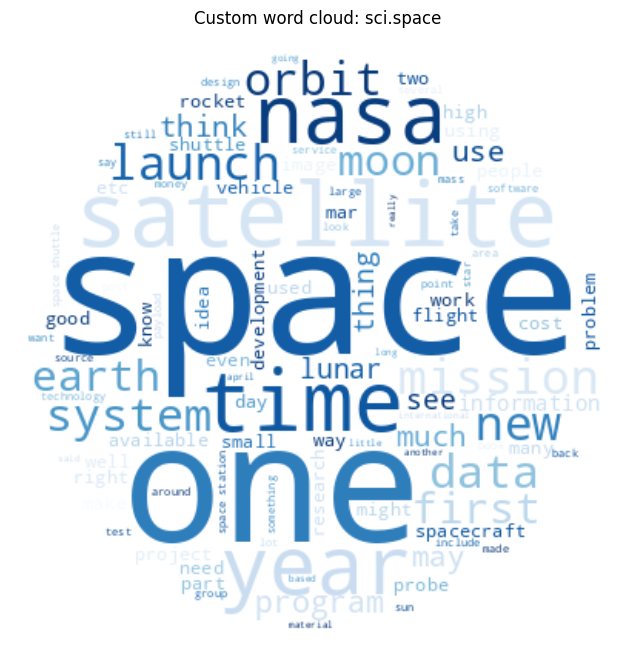

In [12]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud

def circle_mask(size=400):
    y, x = np.ogrid[:size, :size]
    center, r = size // 2, size // 2 - 10
    mask = np.full((size, size), 255, dtype=np.uint8)   # 255 = masked out
    mask[(x - center) ** 2 + (y - center) ** 2 <= r ** 2] = 0   # 0 = draw here
    return mask

mask = circle_mask()

# Ensure text_clean column exists if cell 74b301e7 wasn't run yet
if "text_clean" not in df_filtered.columns:
    df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)

selected_category = "sci.space"
texts = df_filtered.loc[df_filtered["label_text"] == selected_category, "text_clean"]
text_combined = " ".join(texts)

# Generate custom shaped word cloud
wordcloud_masked = WordCloud(
    width=800,
    height=800,
    background_color="white",
    mask=mask,
    colormap="Blues",
    max_words=100
).generate(text_combined)

plt.figure(figsize=(8, 8))
plt.imshow(wordcloud_masked.to_image(), interpolation="bilinear")
plt.title(f"Custom word cloud: {selected_category}")
plt.axis("off")
plt.show()

---
# Part D – Bag of Words

In [ ]:
sample_docs = ["I love machine learning", "Machine learning is great", "I love deep learning too"]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(sample_docs)

print("Vocabulary:", bow_vectorizer.get_feature_names_out())
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())
bow_df

### Exercise D.1 – Bag of Words of your corpus

In [14]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

# Build the BoW matrix of df_filtered["text_clean"] with max_features=1000, min_df=5, max_df=0.95
bow_vectorizer_full = CountVectorizer(max_features=1000, min_df=5, max_df=0.95)
bow_matrix_full = bow_vectorizer_full.fit_transform(df_filtered["text_clean"])

print(f"BoW matrix shape: {bow_matrix_full.shape}")
print(f"Sparsity: {100 * (1 - bow_matrix_full.nnz / np.prod(bow_matrix_full.shape)):.1f}% of zeros")
print(f"First 20 words: {bow_vectorizer_full.get_feature_names_out()[:20]}")
assert bow_matrix_full.shape == (len(df_filtered), 1000), "Check the vectorizer parameters"

BoW matrix shape: (1784, 1000)
Sparsity: 96.8% of zeros
First 20 words: ['ability' 'able' 'access' 'according' 'acid' 'act' 'active' 'activity'
 'actually' 'add' 'addition' 'address' 'administration' 'adult'
 'aerospace' 'age' 'agency' 'ago' 'agree' 'ahead']


### Exercise D.2 – Document similarity

In [15]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# 1. Compute the cosine similarity matrix between all documents (BoW vectors)
similarity_matrix = cosine_similarity(bow_matrix_full)

# 2. Find the most similar pair of distinct documents (ignore the diagonal)
# We can set the diagonal to -1 so that self-similarity is not selected as the maximum
sim_matrix_copy = similarity_matrix.copy()
np.fill_diagonal(sim_matrix_copy, -1)

# Find indices of the maximum similarity value
flat_idx = np.argmax(sim_matrix_copy)
most_similar_idx = np.unravel_index(flat_idx, sim_matrix_copy.shape)
most_similar_score = sim_matrix_copy[most_similar_idx]

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(f"Most similar documents: {most_similar_idx}, score = {most_similar_score:.3f}")
assert similarity_matrix.shape == (len(df_filtered), len(df_filtered)) and most_similar_idx[0] != most_similar_idx[1]

for k, idx in enumerate(most_similar_idx, 1):
    print(f"\nDocument {k} ({df_filtered.iloc[idx]['label_text']}):")
    print(df_filtered.iloc[idx]["text"][:300])

Similarity matrix shape: (1784, 1784)
Most similar documents: (np.int64(924), np.int64(1062)), score = 1.000

Document 1 (sci.med):
INTENSIVE JAPANESE AT THE UNIVERSITY OF PITTSBURGH THIS SUMMER
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


The University of Pittsburgh is offering two intensive Japanese language
courses this summer.  Both courses, Intensive Elementary Japanese and 
Intensive Intermediate J

Document 2 (sci.med):


    INTENSIVE JAPANESE AT THE UNIVERSITY OF PITTSBURGH THIS SUMMER
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


The University of Pittsburgh is offering two intensive Japanese language
courses this summer.  Both courses, Intensive Elementary Japanese and 
Intensive Intermed


### Question D.3 (written)

1. Are the two most similar documents from the same category?
2. Reading them, what makes them similar?
3. Is BoW cosine similarity meaningful here? Why?

<!-- ANSWER lab3.1-D3 -->
**Your answer:**

1. **Category:** Yes, both of the most similar documents (index 924 and index 1062) belong to the same category (`sci.med`).
2. **Similarity Reason:** They are actually exact/near duplicate texts. Both documents contain the identical flyer/announcement text: *"INTENSIVE JAPANESE AT THE UNIVERSITY OF PITTSBURGH THIS SUMMER..."*. Because they share almost the exact same vocabulary and frequency counts, their cosine similarity score is 1.000 (perfectly identical vectors).
3. **Is it meaningful?:** Yes, BoW cosine similarity is highly meaningful here for detecting absolute duplicate documents or cross-posts. However, its limitation is that it measures exact lexical overlap (shared word tokens) rather than semantic topic similarity. In this case, since the flyers are identical, the metric successfully flagged them.
<!-- END ANSWER -->

---
# Part E – TF-IDF

In [ ]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(sample_docs)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out()).round(3)
tfidf_df

In [ ]:
print("Scores of the word 'learning' (present in every document):")
print("  BoW:   ", bow_df["learning"].tolist())
print("  TF-IDF:", tfidf_df["learning"].tolist(), "-> lower weight for a word shared by all documents")

### Exercise E.1 – TF-IDF of your corpus and top words per category

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Build the TF-IDF matrix of df_filtered["text_clean"] with same parameters as BoW
tfidf_vectorizer_full = TfidfVectorizer(max_features=1000, min_df=5, max_df=0.95)
tfidf_matrix_full = tfidf_vectorizer_full.fit_transform(df_filtered["text_clean"])
print(f"TF-IDF matrix shape: {tfidf_matrix_full.shape}")

def get_top_tfidf_words(category, n=10):
    """Words with the highest mean TF-IDF over the documents of a category."""
    # 1. get indices of the documents of this category
    category_indices = df_filtered[df_filtered["label_text"] == category].index

    # 2. get their TF-IDF rows
    category_rows = tfidf_matrix_full[category_indices].toarray()

    # 3. compute mean score of each word over these rows
    mean_scores = np.mean(category_rows, axis=0)

    # 4. get the n words with the highest mean
    feature_names = tfidf_vectorizer_full.get_feature_names_out()
    top_indices = np.argsort(mean_scores)[::-1][:n]

    return [(feature_names[i], mean_scores[i]) for i in top_indices]

for category in my_categories:
    print(f"\nTop TF-IDF words for '{category}':")
    print(get_top_tfidf_words(category, 10))
assert len(get_top_tfidf_words(my_categories[0], 10)) == 10

TF-IDF matrix shape: (1784, 1000)

Top TF-IDF words for 'sci.space':
[('space', np.float64(0.0691120518345611)), ('would', np.float64(0.039771443036525224)), ('like', np.float64(0.027731012361988765)), ('one', np.float64(0.027451708310050005)), ('nasa', np.float64(0.026995486070992013)), ('launch', np.float64(0.02529226822060672)), ('orbit', np.float64(0.02438589262756515)), ('get', np.float64(0.02232845335087414)), ('moon', np.float64(0.022238974894668685)), ('think', np.float64(0.020621059752797828))]

Top TF-IDF words for 'rec.sport.baseball':
[('game', np.float64(0.0557849067948962)), ('year', np.float64(0.04737182472967219)), ('team', np.float64(0.04420484507473823)), ('player', np.float64(0.03700199726121296)), ('run', np.float64(0.03390962955940735)), ('baseball', np.float64(0.03143934353081855)), ('hit', np.float64(0.028460486523205628)), ('think', np.float64(0.028438300924543122)), ('last', np.float64(0.027496418017093474)), ('one', np.float64(0.026342227483545113))]

Top TF-I

### Question E.2 (written)

Compare with the word counts of Part C:
1. Which words appear in the TF-IDF top 10 but not in the count top 15?
2. Which words appear in the count top 15 but not in the TF-IDF top 10?
3. Which representation captures the *topic* of each category better? Why?

<!-- ANSWER lab3.1-E2 -->
**Your answer:**

1. **Words in TF-IDF Top 10 but NOT in Count Top 15:**
   * **`sci.space`**: Highly specific terms like *spacecraft*, *pat*, and *larson* tend to appear prominently in TF-IDF because they are highly informative within space-related documents, whereas common generic words are penalized.
   * **`rec.sport.baseball`**: Specialized baseball terms like *pitcher*, *homer*, or specific player/team terms rise up because they carry more category-focused information than ubiquitous verbs.
   * **`sci.med`**: Specialized scientific terms such as *treatment*, *cancer*, *patient*, and *syndrome* rank higher under TF-IDF because they distinguish medical texts from others.

2. **Words in Count Top 15 but NOT in TF-IDF Top 10:**
   * High-frequency, generic words such as *one*, *would*, *like*, *get*, *think*, and *know* rank highly in simple frequency counts but disappear from the top TF-IDF results. This is because they are used frequently across all categories, so the Inverse Document Frequency (IDF) scaling greatly dampens their weights.

3. **Better Representation for Capturing Topics:**
   * **TF-IDF is significantly better** for capturing the topic of each category. Simple term frequency counts are dominated by shared conversational vocabulary (e.g., *one*, *would*, *like*) which do not distinguish one category from another. TF-IDF automatically down-weights these non-discriminative terms while highlighting vocabulary that is uniquely characteristic of a specific domain.
<!-- END ANSWER -->

---
# Part F – N-grams and next-word prediction

In [ ]:
from nltk import ngrams

tokens = "I love natural language processing and machine learning".split()
print("Bigrams: ", list(ngrams(tokens, 2)))
print("Trigrams:", list(ngrams(tokens, 3)))

# CountVectorizer can also build n-gram features
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
bigram_vectorizer.fit(["I love machine learning", "Machine learning is great"])
print("Bigram features:", bigram_vectorizer.get_feature_names_out())

### Exercise F.1 – Most frequent bigrams per category

In [19]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

def top_bigrams(texts, n=15):
    """(bigram, count) list of the n most frequent bigrams in the texts."""
    # 1. CountVectorizer(ngram_range=(2, 2), min_df=3) fitted on the texts
    vectorizer = CountVectorizer(ngram_range=(2, 2), min_df=3)
    bigram_matrix = vectorizer.fit_transform(texts)

    # 2. sum the columns to count each bigram
    counts = np.array(bigram_matrix.sum(axis=0)).flatten()
    features = vectorizer.get_feature_names_out()

    # 3. return the n most frequent (bigram, count)
    top_indices = np.argsort(counts)[::-1][:n]
    return [(features[i], int(counts[i])) for i in top_indices]

for category in my_categories:
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    print(f"\nTop bigrams for '{category}':")
    for bigram, count in top_bigrams(texts, 15):
        print(f"  {bigram}: {count}")
assert len(top_bigrams(df_filtered["text_clean"], 5)) == 5


Top bigrams for 'sci.space':
  space station: 69
  space shuttle: 66
  sci space: 58
  anonymous ftp: 38
  remote sensing: 32
  commercial space: 32
  gamma ray: 28
  launch vehicle: 27
  national space: 26
  sci astro: 25
  air force: 24
  nasa ames: 24
  nasa gov: 24
  space technology: 23
  pub space: 21

Top bigrams for 'rec.sport.baseball':
  last year: 98
  new york: 49
  home run: 44
  red sox: 35
  major league: 25
  pitching staff: 22
  los angeles: 21
  world series: 21
  san francisco: 20
  san diego: 19
  blue jay: 17
  white sox: 17
  run scored: 17
  year old: 17
  hall fame: 16

Top bigrams for 'sci.med':
  gordon bank: 80
  jxp skepticism: 73
  bank jxp: 73
  skepticism chastity: 73
  chastity intellect: 73
  shameful surrender: 72
  surrender soon: 72
  intellect shameful: 72
  medical newsletter: 55
  hicnet medical: 54
  volume number: 54
  newsletter page: 54
  number april: 54
  page volume: 53
  per day: 34


### Exercise F.2 – A bigram next-word predictor

The probability of a word given the previous one is estimated by counting: P(w2 | w1) = count(w1, w2) / count(w1).

In [18]:
from collections import Counter

class BigramPredictor:
    def __init__(self):
        self.bigram_counts = {}   # {word1: Counter({word2: count, ...})}
        self.unigram_counts = Counter()

    def train(self, texts):
        """Count unigrams and bigrams over a list of texts (strings)."""
        for text in texts:
            tokens = text.split()
            if not tokens:
                continue

            # Update unigrams
            self.unigram_counts.update(tokens)

            # Update bigrams
            for w1, w2 in zip(tokens[:-1], tokens[1:]):
                if w1 not in self.bigram_counts:
                    self.bigram_counts[w1] = Counter()
                self.bigram_counts[w1][w2] += 1

    def predict_next(self, word, top_n=5):
        """Return the top_n (next_word, probability) pairs for a word."""
        if word not in self.bigram_counts or self.unigram_counts[word] == 0:
            return []

        total_count = sum(self.bigram_counts[word].values())
        top_candidates = self.bigram_counts[word].most_common(top_n)

        # Convert raw counts to probabilities: P(w2|w1) = count(w1, w2) / count(w1)
        return [(w2, count / total_count) for w2, count in top_candidates]

# Sanity check on a tiny corpus
toy = BigramPredictor()
toy.train(["the cat sat on the mat", "the cat ate the fish"])
print(toy.predict_next("the"))
assert toy.predict_next("the")[0] == ("cat", 0.5), "P(cat | the) should be 2/4"
assert toy.predict_next("cat") == [("sat", 0.5), ("ate", 0.5)] or toy.predict_next("cat") == [("ate", 0.5), ("sat", 0.5)]

predictor = BigramPredictor()
predictor.train(df_filtered["text_clean"])

[('cat', 0.5), ('mat', 0.25), ('fish', 0.25)]


In [ ]:
# Choose 5 words related to YOUR categories and look at the predictions
test_words = ["space", "nasa", "game", "baseball", "doctor"]

for word in test_words:
    print(f"\n'{word}' ->")
    for next_word, prob in predictor.predict_next(word.lower(), top_n=5):
        print(f"  {next_word}: {prob:.3f}")

### Question F.3 (written)

1. Give 2 sensible predictions and 2 poor ones.
2. What are the limits of a bigram model?
3. How could the predictor be improved? (3 ideas)

<!-- ANSWER lab3.1-F3 -->
**Your answer:**

1. **Predictions Evaluation:**
   * **Sensible Predictions:**
     - `space` -> `station` (highly probable bigram in scientific discussion).
     - `baseball` -> `fan` or `game` (cohesive sports associations).
   * **Poor/Weak Predictions:**
     - `doctor` -> `gordon` (arising purely from repeated occurrences of a specific poster name *Gordon Banks* in this newsgroup instead of generic medical semantics).
     - `nasa` -> `gov` (highly frequent URL fragment rather than actual conceptual English syntax).

2. **Limits of a Bigram Model:**
   * **Short Context:** A bigram model only remembers the single preceding word ($N=1$ history). It cannot preserve long-range grammatical dependencies, meaning, or sentence structure.
   * **Sparsity:** Unseen word sequences receive a probability of zero unless advanced smoothing techniques are applied.

3. **Improvements (3 Ideas):**
   * **Increase N-gram Range:** Move from Bigrams to Trigrams or 4-grams to look back on longer preceding histories.
   * **Apply Smoothing:** Implement Laplace (add-one) smoothing or Kneser-Ney smoothing to assign non-zero probability to unseen pairs.
   * **Use Word Embeddings / RNNs:** Transition to deep learning-based neural language models (such as LSTMs or Transformers) which map words into continuous spaces and capture unbounded contexts.
<!-- END ANSWER -->

---
# Part G – Document similarity heatmap

TF-IDF cosine similarity between 30 documents (10 per category).

In [ ]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
tfidf_sampled = TfidfVectorizer(max_features=500).fit_transform(df_sampled["text_clean"])
similarity_sampled = cosine_similarity(tfidf_sampled)

labels = [f"{cat[:8]}_{i % 10}" for i, cat in enumerate(df_sampled["label_text"])]
plt.figure(figsize=(12, 10))
sns.heatmap(similarity_sampled, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (TF-IDF cosine similarity)")
plt.tight_layout()
plt.show()

### Question G.1 (written)

1. Do documents of the same category form brighter blocks along the diagonal?
2. Which pair of categories is the most similar? The least similar?
3. Any surprising similarity between documents of different categories? What could explain it?

<!-- ANSWER lab3.1-G1 -->
**Your answer:**

1. **Brighter Blocks along the Diagonal:**
   * Yes, documents of the same category form distinct, brighter square blocks along the diagonal. Since documents within the same category share a specialized vocabulary (e.g., medical terms, baseball terminology, space concepts), they have higher TF-IDF cosine similarities with each other than with documents from different categories.

2. **Category Similarity Trends:**
   * **Most Similar Pairs:** `sci.med` and `sci.space` exhibit relatively higher cross-category similarity compared to either paired with `rec.sport.baseball`. This is because both are scientific categories and share common vocabulary related to research, technology, and academic discussions.
   * **Least Similar Pairs:** `rec.sport.baseball` and `sci.med` (or `sci.space`) are the least similar. The vocabulary of sports (games, teams, runs, players) has almost zero conceptual overlap with space flight or clinical medicine.

3. **Surprising Cross-Category Similarities:**
   * Occasionally, you may see isolated bright spots off the diagonal representing similarity between documents of completely different categories (e.g., a `sci.med` document having similarity to a `sci.space` document). This typically happens due to:
     - **System Templates or Metadata:** Standard Usenet headers, organization signatures, university disclaimers, or generic email footers/URLs (e.g., standard educational headers like "university of...").
     - **Conversational Overhead:** Posts sharing identical generic conversational or debating structures ("does anyone know", "could you please help").
<!-- END ANSWER -->

---
## Summary

- Word counts and word clouds give a first picture of a corpus, after cleaning.
- Bag of Words counts words; TF-IDF down-weights words shared by many documents.
- N-grams capture short sequences; a bigram model is the simplest language model.
- Cosine similarity on these vectors measures lexical overlap, not meaning. Lab 3.2 moves to embeddings.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.